Temperature distribution in the grid:
[[  0.     0.     0.     0.     0.     0.  ]
 [100.    72.73  73.11  84.47 113.64 200.  ]
 [100.   117.8  135.23 151.14 170.08 200.  ]
 [100.   163.26 198.86 214.77 215.53 200.  ]
 [100.   236.36 282.2  293.56 277.27 200.  ]
 [400.   400.   400.   400.   400.   400.  ]]


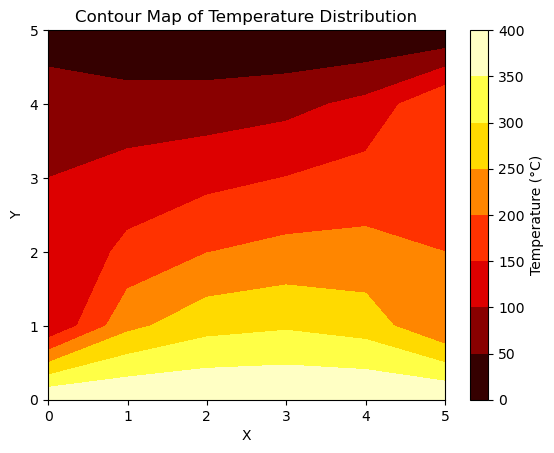

In [1]:
import numpy as np
import matplotlib.pyplot as plt

nx, ny = 6, 6
top_temp = 0
bottom_temp = 400
left_temp = 100
right_temp = 200

A = np.zeros((nx*ny, nx*ny))
B = np.zeros(nx*ny)

def idx(i, j):
    return i * nx + j

for i in range(ny):
    for j in range(nx):
        k = idx(i, j)
        if i == 0:  # Top boundary
            A[k, k] = 1
            B[k] = top_temp
        elif i == ny-1:  # Bottom boundary
            A[k, k] = 1
            B[k] = bottom_temp
        elif j == 0:  # Left boundary
            A[k, k] = 1
            B[k] = left_temp
        elif j == nx-1:  # Right boundary
            A[k, k] = 1
            B[k] = right_temp
        else:  
            A[k, k] = -4
            A[k, idx(i+1, j)] = 1
            A[k, idx(i-1, j)] = 1
            A[k, idx(i, j+1)] = 1
            A[k, idx(i, j-1)] = 1

T = np.linalg.solve(A, B)
T = T.reshape((ny, nx))

np.set_printoptions(precision=2, linewidth=400)

print("Temperature distribution in the grid:")
print(T)

X, Y = np.meshgrid(range(nx), range(ny))
plt.contourf(X, Y[::-1], T, cmap='hot')
plt.colorbar(label='Temperature (°C)')
plt.title('Contour Map of Temperature Distribution')
plt.xlabel('X')
plt.ylabel('Y')
plt.show()

In [2]:
import numpy as np
from fractions import Fraction

A = np.array([[2, 3, -1, 1],
              [4, -1, 2, 7],
              [-1, 2, 3, 4]], dtype=object)

for i in range(A.shape[0]):
    for j in range(A.shape[1]):
        A[i, j] = Fraction(A[i, j])

def gauss_jordan(A):
    rows, cols = A.shape
    for i in range(rows):
        
        A[i] = A[i] / A[i, i]
        for j in range(rows):
            if i != j:
                A[j] = A[j] - A[i] * A[j, i]
    return A

result = gauss_jordan(A)

solutions = result[:, -1]

print("The solution is:")
for i, solution in enumerate(solutions):
    print(f"x{i + 1} = {solution}")

print("\nFinal augmented matrix:")
print(result)

The solution is:
x1 = 64/63
x2 = 11/63
x3 = 14/9

Final augmented matrix:
[[Fraction(1, 1) Fraction(0, 1) Fraction(0, 1) Fraction(64, 63)]
 [Fraction(0, 1) Fraction(1, 1) Fraction(0, 1) Fraction(11, 63)]
 [Fraction(0, 1) Fraction(0, 1) Fraction(1, 1) Fraction(14, 9)]]
